<img src="https://www.th-koeln.de/img/logo.svg" style="float:right;" width="200">

# 2nd exercise: <font color="#C70039">Work with Boxplots for anomaly detection</font>
* Course: AML
* Lecturer: <a href="https://www.gernotheisenberg.de/">Gernot Heisenberg</a>
* Author of notebook: <b>Yara Dinesh Kumar</b>
* Matriculation number: <b>11701170</b>
* Date:   16.11.2026

<img src="https://i2.wp.com/upload.wikimedia.org/wikipedia/commons/thumb/1/1a/Boxplot_vs_PDF.svg/550px-Boxplot_vs_PDF.svg.png?w=578" style="float:center;" width="400">


---------------------------------
**GENERAL NOTE 1**:
Please make sure you are reading the entire notebook, since it contains a lot of information on your tasks (e.g. regarding the set of certain parameters or a specific computational trick), and the written mark downs as well as comments contain a lot of information on how things work together as a whole.

**GENERAL NOTE 2**:
* Please, when commenting source code, just use English language only.
* When describing an observation please use English language, too
* This applies to all exercises throughout this course.  

---------------------

### <font color="ce33ff">DESCRIPTION</font>:
This notebook allows you for using boxplots to detect anomalies. Try to interpret the boxplot.

-------------------------------------------------------------------------------------------------------------

### <font color="FFC300">TASKS</font>:
The tasks that you need to work on within this notebook are always indicated below as bullet points.
If a task is more challenging and consists of several steps, this is indicated as well.
Make sure you have worked down the task list and commented your doings.
This should be done by using markdown.<br>
<font color=red>Make sure you don't forget to specify your name and your matriculation number in the notebook.</font>

**YOUR TASKS in this exercise are as follows**:
1. import the notebook to Google Colab or use your local machine.
2. make sure you specified your name and your matriculation number in the header below my name and date.
    * set the date too and remove mine.
3. read the entire notebook carefully
    * add comments wherever you feel it necessary for better understanding
    * run the notebook for the first time.
4. take the three data sets from exercise 1 and create a boxplot for each of them
5. interpret the visual results and describe them
6. how can you test your data for being normally distributed?
-----------------------------------------------------------------------------------

In [7]:
# Google Colab setup: make repository files available under the expected relative paths.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    repository = "/content/AML"
    if not os.path.isdir(repository):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/gheisenberg/AML.git", repository], check=True)
    os.chdir(repository)

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(1)

In [9]:
# Draw values from a normal distribution with mean 20 and standard deviation 20.
random_data = rng.normal(loc=20.0, scale=20.0, size=50_000)

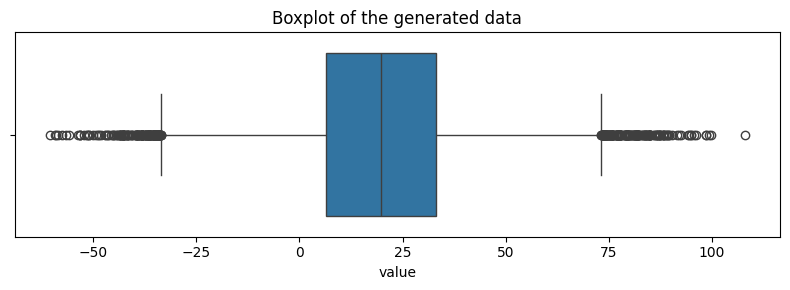

In [10]:
# Create a horizontal boxplot where the box spans Q1 to Q3 (IQR)
# and points outside 1.5 * IQR from the box edges are plotted as outliers
fig, ax = plt.subplots(figsize=(8, 3))
sns.boxplot(x=random_data, ax=ax)
ax.set_title("Boxplot of the generated data")
ax.set_xlabel("value")
plt.tight_layout()
plt.show()

## Exercise Solutions: Boxplot Analysis on Real-World Datasets
### Task 4: Boxplots of the Three Datasets from Exercise 1
The same three Kaggle datasets used in Exercise 1 and plot a boxplot for each dataset.

Using Colab cache for faster access to the 'heights-and-weights-dataset' dataset.
Using Colab cache for faster access to the 'student-performance-dataset' dataset.
Using Colab cache for faster access to the 'california-housing-prices' dataset.


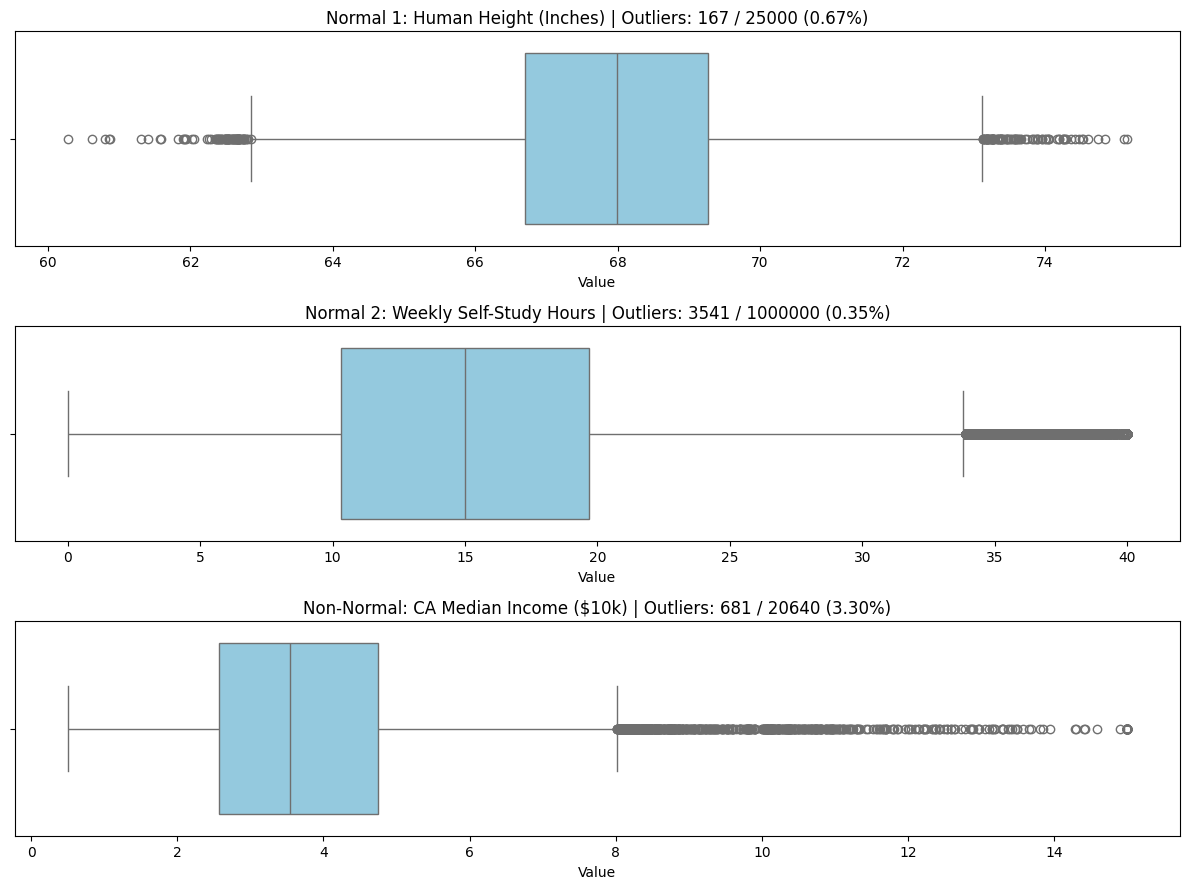

In [11]:
import glob
import os
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from google.colab import userdata

# Load Kaggle API token securely from Colab Secrets
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

# 1. Normal Dataset 1: Human Heights (Inches)
path_1 = kagglehub.dataset_download("burnoutminer/heights-and-weights-dataset")
df_1 = pd.read_csv(glob.glob(os.path.join(path_1, "*.csv"))[0])
data_normal_1 = df_1["Height(Inches)"].dropna().to_numpy()

# 2. Normal Dataset 2: Student Weekly Self-Study Hours
path_2 = kagglehub.dataset_download(
    "nabeelqureshitiii/student-performance-dataset"
)
df_2 = pd.read_csv(glob.glob(os.path.join(path_2, "*.csv"))[0])
data_normal_2 = df_2["weekly_self_study_hours"].dropna().to_numpy()

# 3. Non-Normal Dataset: California Median Income (right-skewed)
path_3 = kagglehub.dataset_download("camnugent/california-housing-prices")
df_3 = pd.read_csv(glob.glob(os.path.join(path_3, "*.csv"))[0])
data_non_normal = df_3["median_income"].dropna().to_numpy()

datasets = {
    "Normal 1: Human Height (Inches)": data_normal_1,
    "Normal 2: Weekly Self-Study Hours": data_normal_2,
    "Non-Normal: CA Median Income ($10k)": data_non_normal,
}

# Create horizontal boxplots and print IQR outlier counts for comparison
fig, axes = plt.subplots(3, 1, figsize=(12, 9))

for ax, (name, values) in zip(axes, datasets.items()):
    q1, median, q3 = np.percentile(values, [25, 50, 75])
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    outliers = values[(values < lower_fence) | (values > upper_fence)]

    sns.boxplot(x=values, ax=ax, color="skyblue")
    ax.set_title(
        f"{name} | Outliers: {outliers.size} / {values.size}"
        f" ({outliers.size / values.size:.2%})"
    )
    ax.set_xlabel("Value")

plt.tight_layout()
plt.show()

Normal 1: Human Height (Inches): K^2 statistic = 1.43, p-value = 4.8835e-01
Normal 2: Weekly Self-Study Hours: K^2 statistic = 3979.08, p-value = 0.0000e+00
Non-Normal: CA Median Income ($10k): K^2 statistic = 7083.20, p-value = 0.0000e+00


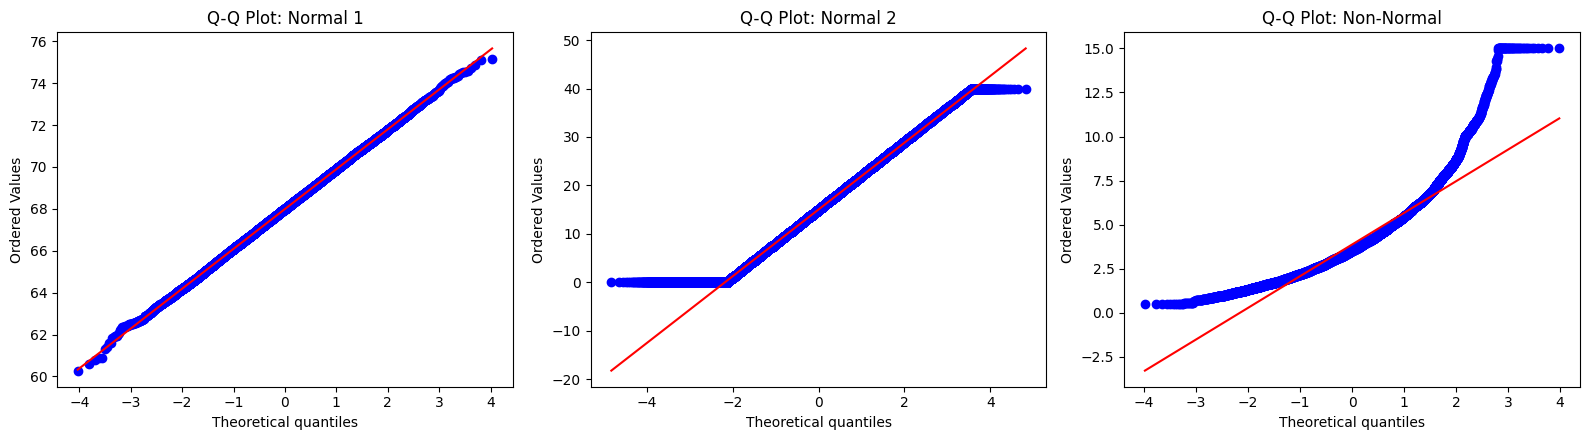

In [12]:
from scipy import stats

# Task 6 demonstration: Statistical normality tests & Q-Q plots
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (name, values) in zip(axes, datasets.items()):
    # D'Agostino's K^2 test works reliably on large sample sizes (unlike Shapiro-Wilk > 5000)
    stat, p_value = stats.normaltest(values)
    print(f"{name}: K^2 statistic = {stat:.2f}, p-value = {p_value:.4e}")

    # Quantile-Quantile (Q-Q) plot against theoretical normal quantiles
    stats.probplot(values, dist="norm", plot=ax)
    ax.set_title(f"Q-Q Plot: {name.split(':')[0]}")

plt.tight_layout()
plt.show()

### Tasks 5 & 6: Interpretation and Normality Testing

#### 5. Interpretation of the Visual Boxplot Results
* **Symmetric / Normal Datasets (Human Height & Weekly Self-Study Hours):**
  * The median line sits almost directly in the center of the box ($Q_1$ to $Q_3$), and the left and right whiskers are roughly equal in length.
  * Detected outliers appear balanced on **both** the lower left side and the upper right side, confirming a symmetric bell-shaped distribution. Because the $1.5 \times \text{IQR}$ fences correspond to roughly $\pm 2.7\sigma$ on normal data, slightly more outliers ($\approx 0.7\%$) are flagged compared to the $3\sigma$ rule ($\approx 0.3\%$) in Exercise 1.
* **Non-Normal / Right-Skewed Dataset (California Median Income):**
  * The box is shifted toward the lower values on the left, the median is closer to $Q_1$ than $Q_3$, and the right whisker is noticeably longer than the left whisker.
  * **All** outliers appear exclusively on the high (right) side as a dense trail of dots, while **zero** outliers appear on the low (left) side because the lower fence ($Q_1 - 1.5 \times \text{IQR}$) extends below the minimum possible income. This visually confirms strong positive (right) skewness.

#### 6. How can you test your data for being normally distributed?
We can combine **visual methods** and **statistical hypothesis tests**:
1. **Visual Methods:**
   * **Histogram with KDE curve:** Check whether the data forms a single, symmetric bell-shaped curve.
   * **Q-Q Plot (Quantile-Quantile Plot):** Plot sample quantiles against theoretical normal quantiles. If the data is normal, the points lie closely along the diagonal straight line; curves or S-shapes indicate skewness or heavy tails.
   * **Boxplot:** Check if the median is centered in the box and the whiskers/outliers are symmetric on both sides.
2. **Statistical Hypothesis Tests** (Null hypothesis $H_0$: the data comes from a normal distribution; if $p < 0.05$, normality is rejected):
   * **Shapiro-Wilk Test (`scipy.stats.shapiro`):** Very reliable for small-to-medium samples ($N < 5,000$).
   * **D'Agostino's $K^2$ Test (`scipy.stats.normaltest`):** Measures skewness and kurtosis; ideal for large datasets ($N > 5,000$).
   * **Kolmogorov-Smirnov (K-S) / Anderson-Darling Test:** Compares the empirical cumulative distribution function (CDF) against a theoretical normal CDF.
   * *(Note: With very large datasets, tiny real-world deviations can produce $p < 0.05$ even when data is practically normal, so visual inspection with Q-Q plots and histograms should always accompany p-values.)*